In [ ]:
#!/usr/bin/env python3
"""
run_simulation.py

Lightweight runner to exercise the la_* pipeline with simulated antenna data.

Usage examples:
  # run 5 steps using explicit coordinate sequences
  python scripts/run_simulation.py --mode coords --steps 5 --outdir /tmp/alma_sim

  # run 10 steps using bit-based simulation (uses ant_pos.2.txt mapping)
  python scripts/run_simulation.py --mode bits --steps 10 --outdir /tmp/alma_sim

The script will call the same pipeline functions used by la_main: baselines,
UV coverage, masked FFT and dirty image creation and save outputs per step.
"""
import os
import argparse
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import astropy.units as u
import logging

# Import project modules (must run from project root)
from la_obs_img import Observatory, SkyImage, Observation
from la_control import Control
import la_config


def ensure_dir(p):
    os.makedirs(p, exist_ok=True)


def save_image(arr, fname, cmap='inferno'):
    # ensure real-valued image for plotting
    if np.iscomplexobj(arr):
        arr = np.abs(arr)
    plt.figure(figsize=(6,6))
    plt.imshow(arr, origin='lower', cmap=cmap)
    plt.colorbar()
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.close()


def run_coords_mode(outdir, steps, img_path):
    # simple deterministic coordinate sequences for testing
    alma = Observatory(ant_pos_bit_file='./ant_pos.2.txt')
    # No need to load bit file for coords mode, but safe to do so
    try:
        alma.load_ant_pos_bit_file()
    except Exception:
        pass

    # create sky image and observation
    dirpath = os.path.dirname(img_path) or './models/'
    if not dirpath.endswith('/'):
        dirpath += '/'
    imgobj = SkyImage(path=dirpath, filename=os.path.basename(img_path))
    imgobj.load_image()
    imgobj.make_invert()

    cont = Control(ctrl_id='SIM')
    cont.add_buttons()
    cont.set_but_bit_dict_file('but_dict.pickle')
    try:
        cont.load_but_bit_dict()
    except Exception:
        pass
    cont.set_swi_bit_list(la_config.swi_bits)

    obs = Observation(alma, imgobj, cont, obs_frequency=200*u.GHz, var_dic=la_config.var_dic)

    # generate a few synthetic antenna configurations
    rng = np.random.default_rng(42)
    n_ant = 6
    for i in range(steps):
        # jitter positions around a small layout
        ew = np.linspace(0, 10, n_ant) + rng.normal(scale=1.0, size=n_ant)
        ns = np.linspace(0, -5, n_ant) + rng.normal(scale=1.0, size=n_ant)
        alma.ant_pos_EW = np.array(ew)
        alma.ant_pos_NS = np.array(ns)
        alma.ant_pos_X = -1 * alma.ant_pos_NS * np.sin(alma.latitude)
        alma.ant_pos_Y = alma.ant_pos_EW
        alma.ant_pos_Z = alma.ant_pos_NS * np.cos(alma.latitude)

        alma.make_baselines()
        obs.calc_el_curve()
        obs.make_uv_coverage()
        obs.grid_uv_coverage()
        obs.make_masked_arr()
        obs.make_dirty_arr()

        # save outputs
        step_dir = os.path.join(outdir, f'step_{i:03d}')
        ensure_dir(step_dir)
        np.save(os.path.join(step_dir, 'dirty_image.npy'), obs.dirty_image)
        np.save(os.path.join(step_dir, 'uv_coverage.npy'), obs.UVC)
        save_image(obs.dirty_image, os.path.join(step_dir, 'dirty_image.png'))
        print(f'[coords] saved step {i} → {step_dir}')


def run_bits_mode(outdir, steps, img_path, use_bits_count=6):
    alma = Observatory(ant_pos_bit_file='./ant_pos.2.txt')
    alma.load_ant_pos_bit_file()

    # extract available bit ids
    bit_ids = list(alma._ant_bit_dict.keys())
    if len(bit_ids) == 0:
        raise RuntimeError('No antenna bit mapping loaded from ant_pos.2.txt')

    dirpath = os.path.dirname(img_path) or './models/'
    if not dirpath.endswith('/'):
        dirpath += '/'
    imgobj = SkyImage(path=dirpath, filename=os.path.basename(img_path))
    imgobj.load_image()
    imgobj.make_invert()

    cont = Control(ctrl_id='SIM')
    cont.add_buttons()
    cont.set_swi_bit_list(la_config.swi_bits)

    obs = Observation(alma, imgobj, cont, obs_frequency=200*u.GHz, var_dic=la_config.var_dic)

    rng = np.random.default_rng(1)
    for i in range(steps):
        # pick a random subset of bits to simulate antennas present
        k = min(use_bits_count, len(bit_ids))
        selected = rng.choice(bit_ids, size=k, replace=False)
        fake_last = {'/dev/ttyUSB0': np.array(selected)}
        alma.set_read_source_ids(['/dev/ttyUSB0'])
        alma.set_ant_pos(fake_last)
        alma.make_baselines()

        obs.calc_el_curve()
        obs.make_uv_coverage()
        obs.grid_uv_coverage()
        obs.make_masked_arr()
        obs.make_dirty_arr()

        step_dir = os.path.join(outdir, f'step_{i:03d}')
        ensure_dir(step_dir)
        np.save(os.path.join(step_dir, 'dirty_image.npy'), obs.dirty_image)
        np.save(os.path.join(step_dir, 'uv_coverage.npy'), obs.UVC)
        save_image(obs.dirty_image, os.path.join(step_dir, 'dirty_image.png'))
        print(f'[bits] saved step {i} (bits={selected.tolist()}) → {step_dir}')


def main():
    parser = argparse.ArgumentParser(description='Run la_* pipeline with simulated antenna data')
    parser.add_argument('--mode', choices=['coords', 'bits'], default='coords')
    parser.add_argument('--steps', type=int, default=5)
    parser.add_argument('--outdir', type=str, default='./sim_outputs')
    parser.add_argument('--img', type=str, default='./models/galaxy_lobes.png')
    parser.add_argument('--bits-count', type=int, default=6,
                        help='number of antenna bits to choose when in bits mode')
    args = parser.parse_args()

    ensure_dir(args.outdir)

    logging.basicConfig(level=logging.INFO)
    print('Starting simulation runner, mode=', args.mode)

    if args.mode == 'coords':
        run_coords_mode(args.outdir, args.steps, args.img)
    else:
        run_bits_mode(args.outdir, args.steps, args.img, use_bits_count=args.bits_count)


if __name__ == '__main__':
    main()


Gebrauchsanweisung — `run_simulation.py`

Kurz: Dieses Skript simuliert Antennenpositionen und führt die `la_`-Pipeline (Baselines, UV-Abdeckung, Maskierung, Dirty Image) aus. Es speichert pro Schritt die Dateien `dirty_image.npy`, `uv_coverage.npy` und `dirty_image.png` im angegebenen Ausgabeordner.

Voraussetzungen
- Aktiviere das Projekt-`venv` oder stelle sicher, dass die benötigten Pakete installiert sind (numpy, astropy, matplotlib, scipy, pillow).
- Aus dem Projektstamm ausführen, damit die lokalen Module importierbar sind.

Beispiele (Terminal)

- Kurzer Test (coords, 1 Schritt):

```
PYTHONPATH=. .venv/bin/python scripts/run_simulation.py --mode coords --steps 1 --outdir /tmp/alma_sim_test
```

- Bits-Modus (10 Schritte):

```
PYTHONPATH=. .venv/bin/python scripts/run_simulation.py --mode bits --steps 10 --outdir ./sim_outputs --bits-count 6
```

Parameter
- `--mode`: `coords` (direkte EW/NS-Koordinaten) oder `bits` (simulierte Bit-IDs, liest `ant_pos.2.txt`).
- `--steps`: Anzahl der Simulationsschritte.
- `--outdir`: Zielordner für die Ausgabe je Schritt.
- `--img`: Pfad/Dateiname des Input-Bildes (Standard: `./models/galaxy_lobes.png`).
- `--bits-count`: Anzahl der zufällig gewählten Antennenbits im `bits`-Modus.

Hinweise
- Wenn du das Notebook-Environment nutzt, setze `PYTHONPATH` so, dass die Projektmodule importierbar sind (z. B. `PYTHONPATH=.`).
- Bei Problemen mit Bildlade-/FFT-Schritten prüfe, ob `models/galaxy_lobes.png` vorhanden ist oder passe `--img` an.
- Ausgabe: Pro Schritt wird ein Unterordner `step_XXX` mit `.npy`- und `.png`-Dateien erzeugt.

Fragen oder Erweiterungswünsche? Ich kann die Anleitung erweitern oder ein kurzes `README.md` hinzufügen.

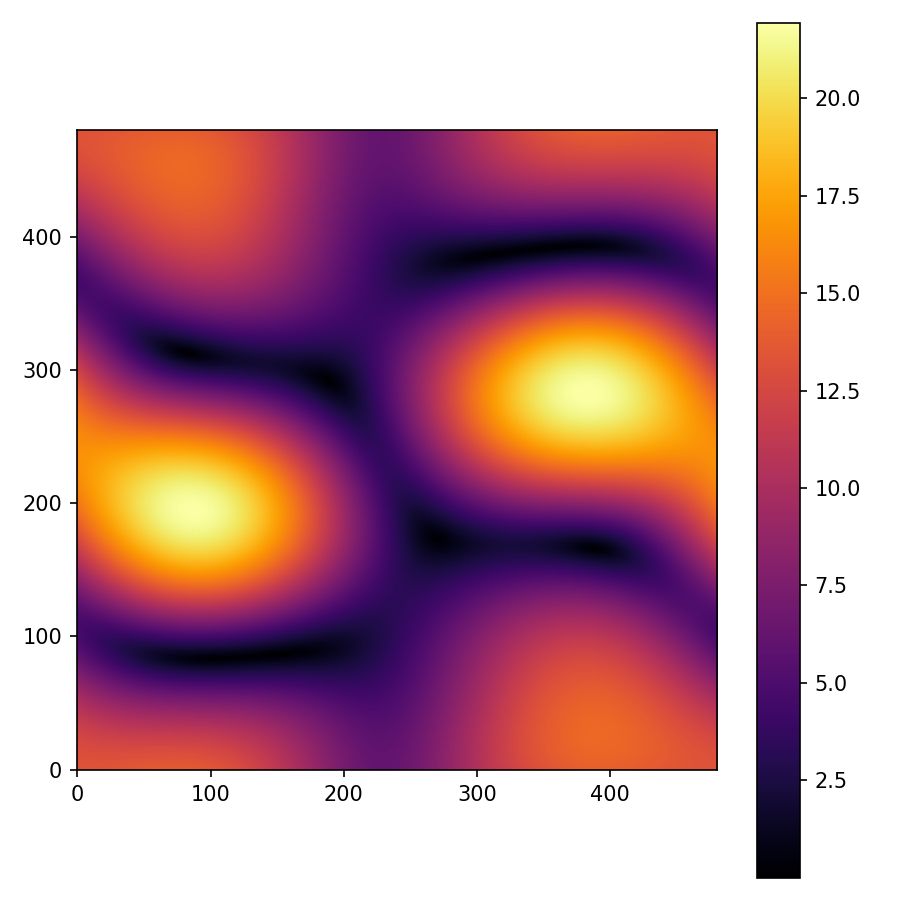

In [4]:
from IPython.display import Image, display
display(Image('/tmp/alma_sim_test/step_000/dirty_image.png'))